# APDS TP03 — Gemma 3 Fine-Tuning


## Configuration


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import pandas as pd

# Restart the kernel before changing experiments.
EXPERIMENT = "acleda_4epochs"
EXPERIMENTS = {
    "acleda_2epochs": ("dataasilida_cleaned.csv", "acleda", 2),
    "khmerqa_2epochs": ("khmer_wikipedia_qa.csv", "khmerqa", 2),
    "acleda_4epochs": ("dataasilida_cleaned.csv", "acleda", 4),
    "acleda_lr5e5_2epochs": ("dataasilida_cleaned.csv", "acleda", 2),
}
DATA_FILENAME, RUN, NUM_TRAIN_EPOCHS = EXPERIMENTS[EXPERIMENT]
DATA_PATH = Path(DATA_FILENAME)
BANKING_AUDIT = RUN == "acleda"

LORA_RANK = 8
LORA_ALPHA = 8
# Evaluate the complete held-out test split after choosing settings on validation.
EVAL_LIMIT = None
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")


In [3]:
MODEL_NAME = "unsloth/gemma-3-4b-it-unsloth-bnb-4bit"
MAX_SEQ_LENGTH = 2048
LEARNING_RATE = 2e-4
if EXPERIMENT == "acleda_lr5e5_2epochs":
    LEARNING_RATE = 5e-5
BATCH_SIZE = 1
ACCUMULATION_STEPS = 8
EVAL_STEPS = 10
SEED = 3407

MAX_NEW_TOKENS = 768
REPETITION_PENALTY = 1.1
NO_REPEAT_NGRAM_SIZE = 8


In [4]:
RUN_ID = f"{EXPERIMENT}-{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}"
RUN_DIR = Path("outputs") / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Dataset:", DATA_FILENAME)
print("Experiment:", EXPERIMENT)


Dataset: dataasilida_cleaned.csv
Experiment: acleda_4epochs


## Load prepared data


In [5]:
from prepare_data import load_prepared, key
PREPARED_DIR = Path("data_prepared") / RUN
data = pd.read_csv(PREPARED_DIR / "dataasilida_training_candidate.csv")
splits, cleaning_manifest = load_prepared(
    directory=PREPARED_DIR,
    source=DATA_PATH,
    banking_audit=BANKING_AUDIT,
)
manifest_path = RUN_DIR / "cleaning_manifest.json"
manifest_content = json.dumps(
    cleaning_manifest,
    ensure_ascii=False,
    indent=2,
)
manifest_path.write_text(manifest_content, encoding="utf-8")
print("Prepared examples:", len(data))


Split sizes: {'train': 241, 'validation': 30, 'test': 32}
Prepared examples: 303


## Load model


In [6]:
from unsloth import FastModel
import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable. Check nvidia-smi and your NVIDIA driver, then restart the uv kernel.")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "CUDA:", torch.version.cuda)


model, tokenizer = FastModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    load_in_4bit=True,
    load_in_8bit=False,
    full_finetuning=False,
)


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1108 16:25:43.845000 21719 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1108 16:25:43.864000 21719 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


🦥 Unsloth Zoo will now patch everything to make training faster!


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch: 2.14.1+cu130 CUDA: 13.0


==((====))==  Unsloth 2026.11.2: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 4060 Laptop GPU. Num GPUs = 1. Max memory: 7.625 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

Unsloth: compiling each transformer block as one region (Gemma3DecoderLayer).


## Tokenize data


In [7]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)


In [8]:
from datasets import Dataset, DatasetDict

prepared_datasets = {}
for split_name, records in splits.items():
    prepared_datasets[split_name] = Dataset.from_pandas(pd.DataFrame(records), preserve_index=False)

dataset = DatasetDict(prepared_datasets)

split_path = RUN_DIR / "splits.json"
split_content = json.dumps(splits, ensure_ascii=False, indent=2)
split_path.write_text(split_content, encoding="utf-8")
SPLIT_SHA256 = hashlib.sha256(split_path.read_bytes()).hexdigest()

for split_name, records in splits.items():
    print(split_name, len(records))


train 241
validation 30
test 32


In [9]:
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)
ASSISTANT_PREFIX = "<start_of_turn>model\n"
END_OF_TURN = "<end_of_turn>"


def formatting_prompts_func(example):
    user = {"role": "user", "content": example["input"]}
    assistant = {"role": "assistant", "content": example["output"]}
    prompt = tokenizer.apply_chat_template([user], add_generation_prompt=True, tokenize=False)
    text = tokenizer.apply_chat_template(
        [user, assistant], add_generation_prompt=False, tokenize=False
    )
    answer_start = len(prompt)
    answer_end = answer_start + len(example["output"])
    stop_end = answer_end + len(END_OF_TURN)
    if (not prompt.endswith(ASSISTANT_PREFIX)
            or text[:stop_end] != prompt + example["output"] + END_OF_TURN
            or text[stop_end:].strip()):
        raise ValueError(f"Unexpected Gemma 3 chat template for {example['input']!r}")

    encoded = text_tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    input_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]
    if len(input_ids) > MAX_SEQ_LENGTH:
        raise ValueError(f"{len(input_ids)} tokens exceeds {MAX_SEQ_LENGTH}: {example['input']!r}")
    # Offsets come from the full text. Separate tokenization of the answer can
    # change its first token when whitespace merges at the template boundary.
    labels = [-100] * len(input_ids)
    for index, (start, end) in enumerate(offsets):
        if start < stop_end and end > answer_start:
            if text[start:answer_start].strip() or text[stop_end:end].strip():
                raise ValueError("A token crosses the assistant turn boundary")
            labels[index] = input_ids[index]
    stop_id = text_tokenizer.convert_tokens_to_ids(END_OF_TURN)
    supervised = [label for label in labels if label != -100]
    if len(supervised) < 2 or supervised[-1] != stop_id or stop_id == text_tokenizer.unk_token_id:
        raise ValueError(f"Missing supervised answer or end-of-turn token: {example['input']!r}")
    return {"text": text, "input_ids": input_ids, "labels": labels}


In [10]:
dataset = dataset.map(formatting_prompts_func)
for name, split in dataset.items():
    lengths = [len(ids) for ids in split["input_ids"]]
    print(f"{name}: {len(split)} records, {min(lengths)} to {max(lengths)} tokens")
print(dataset["train"]["text"][0])


Map:   0%|          | 0/241 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

train: 241 records, 54 to 724 tokens
validation: 30 records, 49 to 616 tokens
test: 32 records, 52 to 742 tokens
<bos><start_of_turn>user
តើខ្ញុំ​អាច​ទទួល​បាន​លេខ​សម្ងាត់​ម្តង ដែល​មាន​៦ខ្ទង់ នៅ​ពេល​ដែល​ខ្ញុំ​នៅ​ក្រៅប្រទេស​ដែរ​ឬទេ<end_of_turn>
<start_of_turn>model
ប្រសិនបើ​លោកអ្នក​នៅ​ក្រៅ​ប្រទេស ហើយ​ប្រើប្រាស់​សេវា​ទូរស័ព្ទ​នៅ​ក្រៅ​ប្រទេស នោះ​លោកអ្នក​មិនអាច​ទទួល​បាន​សារ​លេខ​សម្ងាត់​បានទេ។ ក្នុង​ករណី​លោកអ្នក​នៅ​ក្រៅ​ប្រទេស សូម​បើក​ទូរស័ព្ទដៃ​របស់​លោកអ្នក ដោយ​ដំណើរការ​សេវា​ក្រៅ​ប្រទេស (Roaming) ដើម្បី​ទទួល​បាន​សារ​លេខ​សម្ងាត់ ក្នុង​ការបញ្ចប់​ប្រតិបត្តិការ​អនឡាញ។ សូម​ពិភាក្សា​ជាមួយ​ក្រុមហ៊ុន​ផ្គត់ផ្គង់​បណ្តាញ​សេវា​ទូរស័ព្ទ​ដែល​លោកអ្នក​កំពុង​ប្រើប្រាស់​សម្រាប់​ព័ត៌មាន​លម្អិត។ ទោះបីជា​យ៉ាងណា​ក៏ដោយ លោកអ្នក​នៅតែ​ទទួល​បាន​លេខ​សម្ងាត់​តាមរយៈ​អ៉ីម៉ែល​របស់​លោកអ្នក​ដដែល។<end_of_turn>



In [11]:
import unicodedata

FastModel.for_inference(model)
stop_ids = [
    text_tokenizer.eos_token_id,
    text_tokenizer.convert_tokens_to_ids("<end_of_turn>"),
]
stop_ids = sorted({
    token_id
    for token_id in stop_ids
    if token_id is not None and token_id != text_tokenizer.unk_token_id
})


def unexpected_scripts(text):
    scripts = set()
    for character in text:
        if not character.isalpha():
            continue
        if "\u1780" <= character <= "\u17ff":
            continue
        name = unicodedata.name(character, "")
        if name.startswith("LATIN "):
            continue
        scripts.add(name.split()[0] if name else "UNKNOWN")
    return sorted(scripts)


@torch.inference_mode()
def answer(question):
    messages = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = text_tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to("cuda")

    input_length = inputs["input_ids"].shape[1]
    token_budget = min(MAX_NEW_TOKENS, MAX_SEQ_LENGTH - input_length)
    if token_budget <= 0:
        raise ValueError("The question leaves no space for an answer.")

    output = model.generate(
        **inputs,
        max_new_tokens=token_budget,
        do_sample=False,
        repetition_penalty=REPETITION_PENALTY,
        no_repeat_ngram_size=NO_REPEAT_NGRAM_SIZE,
        eos_token_id=stop_ids,
        pad_token_id=text_tokenizer.pad_token_id,
    )
    generated_ids = output[0, input_length:]
    text = text_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    ).strip()

    ended_turn = (
        len(generated_ids) > 0
        and generated_ids[-1].item() in stop_ids
    )
    hit_limit = len(generated_ids) >= token_budget and not ended_turn

    if hit_limit:
        stop_reason = "generation_limit"
    elif ended_turn:
        stop_reason = "end_of_turn"
    else:
        stop_reason = "other"

    return {
        "text": text,
        "generated_tokens": len(generated_ids),
        "token_budget": token_budget,
        "hit_token_limit": hit_limit,
        "stop_reason": stop_reason,
        "unexpected_scripts": unexpected_scripts(text),
    }


In [12]:
test_rows = splits["test"]
if EVAL_LIMIT is not None:
    test_rows = test_rows[:EVAL_LIMIT]

before_generations = [answer(row["input"]) for row in test_rows]
FastModel.for_training(model)


Gemma3ForConditionalGeneration(
  (model): Gemma3Model(
    (vision_tower): SiglipVisionModel(
      (embeddings): SiglipVisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(4096, 1152)
      )
      (encoder): SiglipEncoder(
        (layers): ModuleList(
          (0-26): 27 x SiglipEncoderLayer(
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True, bias=True)
            (self_attn): SiglipAttention(
              (k_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
              (v_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
              (q_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
              (out_proj): Linear4bit(in_features=1152, out_features=1152, bias=True)
            )
            (layer_norm2): LayerNorm((1152,), eps=1e-06, elementwise_affine=True, bias=True)
            (mlp): Sigl

## LoRA adapters


In [13]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=0,
    bias="none",
    random_state=SEED,
)


## Trainer


In [14]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    args=SFTConfig(
        dataset_text_field="text",
        dataset_kwargs={"skip_prepare_dataset": True},
        max_length=MAX_SEQ_LENGTH,
        dataset_num_proc=1,
        packing=False,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=ACCUMULATION_STEPS,
        warmup_steps=5,
        num_train_epochs=NUM_TRAIN_EPOCHS,
        learning_rate=LEARNING_RATE,
        fp16=False,
        bf16=is_bfloat16_supported(),
        logging_steps=1,
        eval_strategy="steps",
        eval_steps=EVAL_STEPS,
        prediction_loss_only=True,
        save_strategy="steps",
        save_steps=EVAL_STEPS,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="linear",
        seed=SEED,
        output_dir=str(RUN_DIR / "checkpoints"),
        report_to="none",
    ),
)


Unsloth: Turning padding-free batching off, since your dataset is already tokenized and cannot be truncated here. Padding-free batching cannot enforce a `max_length` of 2048.


### Validate labels


In [15]:
# Verify that the trainer and collator preserve every prepared assistant label.
for name, split in (("train", trainer.train_dataset), ("validation", trainer.eval_dataset)):
    columns = ["input_ids", "labels"]
    expected = dataset[name].select_columns(columns)
    actual = split.select_columns(columns)
    if len(expected) != len(actual) or any(a != b for a, b in zip(expected, actual)):
        raise ValueError(f"{name}: SFTTrainer changed token IDs or assistant labels")
    # Use different lengths so the check also covers masked padding.
    short = min(actual, key=lambda row: len(row["input_ids"]))
    long = max(actual, key=lambda row: len(row["input_ids"]))
    rows = [short, long]
    batch = trainer.data_collator(rows)
    for i, row in enumerate(rows):
        active = batch["attention_mask"][i].bool()
        if (batch["input_ids"][i][active].tolist() != row["input_ids"]
                or batch["labels"][i][active].tolist() != row["labels"]
                or (batch["labels"][i][~active] != -100).any()
                or len(active) > MAX_SEQ_LENGTH):
            raise ValueError(f"{name}: the data collator changed assistant labels or padding")
    print(f"{name}: verified assistant-only labels for {len(actual)} examples and checked padding")


train: verified assistant-only labels for 241 examples and checked padding
validation: verified assistant-only labels for 30 examples and checked padding


In [16]:
row = trainer.train_dataset[0]
print(text_tokenizer.decode([label for label in row["labels"] if label != -100]))


ប្រសិនបើ​លោកអ្នក​នៅ​ក្រៅ​ប្រទេស ហើយ​ប្រើប្រាស់​សេវា​ទូរស័ព្ទ​នៅ​ក្រៅ​ប្រទេស នោះ​លោកអ្នក​មិនអាច​ទទួល​បាន​សារ​លេខ​សម្ងាត់​បានទេ។ ក្នុង​ករណី​លោកអ្នក​នៅ​ក្រៅ​ប្រទេស សូម​បើក​ទូរស័ព្ទដៃ​របស់​លោកអ្នក ដោយ​ដំណើរការ​សេវា​ក្រៅ​ប្រទេស (Roaming) ដើម្បី​ទទួល​បាន​សារ​លេខ​សម្ងាត់ ក្នុង​ការបញ្ចប់​ប្រតិបត្តិការ​អនឡាញ។ សូម​ពិភាក្សា​ជាមួយ​ក្រុមហ៊ុន​ផ្គត់ផ្គង់​បណ្តាញ​សេវា​ទូរស័ព្ទ​ដែល​លោកអ្នក​កំពុង​ប្រើប្រាស់​សម្រាប់​ព័ត៌មាន​លម្អិត។ ទោះបីជា​យ៉ាងណា​ក៏ដោយ លោកអ្នក​នៅតែ​ទទួល​បាន​លេខ​សម្ងាត់​តាមរយៈ​អ៉ីម៉ែល​របស់​លោកអ្នក​ដដែល។<end_of_turn>


In [17]:
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")


GPU = NVIDIA GeForce RTX 4060 Laptop GPU. Max memory = 7.625 GB.
4.404 GB of memory reserved.


## Training


In [18]:
trainer_stats = trainer.train()


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 241 | Num Epochs = 4 | Total steps = 124
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
10,1.717205,1.983357
20,1.436661,1.596875
30,1.688570,1.464414
40,1.343860,1.403163
50,1.065516,1.355885
60,1.233877,1.324646
70,1.048700,1.318544
80,1.077010,1.320216
90,1.106425,1.300153
100,1.001784,1.302717


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Filter:   0%|          | 0/30 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


... (22 outputs left out)

Unsloth: Restored added_tokens_decoder metadata in outputs/acleda_4epochs-20261108T092541199378Z/checkpoints/checkpoint-120/tokenizer_config.json.


Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/acleda_4epochs-20261108T092541199378Z/checkpoints/checkpoint-120.


Unsloth: Restored added_tokens_decoder metadata in outputs/acleda_4epochs-20261108T092541199378Z/checkpoints/checkpoint-124/tokenizer_config.json.


Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/acleda_4epochs-20261108T092541199378Z/checkpoints/checkpoint-124.


In [19]:
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")


459.4577 seconds used for training.
7.66 minutes used for training.
Peak reserved memory = 4.67 GB.
Peak reserved memory for training = 0.266 GB.
Peak reserved memory % of max memory = 61.246 %.
Peak reserved memory for training % of max memory = 3.489 %.


## Loss curves


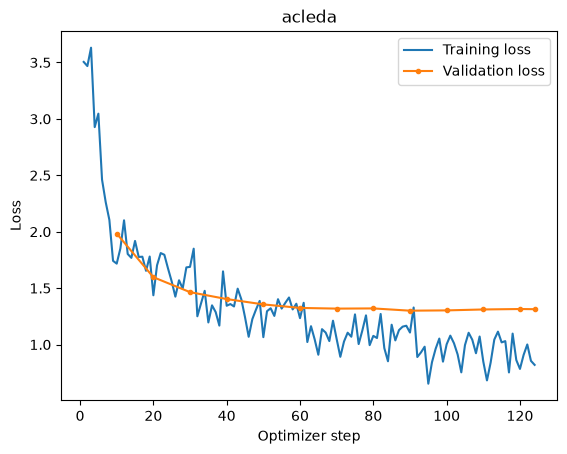

Best validation loss: 1.3002 (step 90)


In [20]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_loss = []
val_loss = []

for record in history:
    step = record.get("step")

    if "loss" in record:
        train_loss.append((step, record["loss"]))

    if "eval_loss" in record:
        val_loss.append((step, record["eval_loss"]))

train_steps, train_values = zip(*train_loss)
validation_steps, validation_values = zip(*val_loss)

plt.plot(train_steps, train_values, label="Training loss")
plt.plot(
    validation_steps,
    validation_values,
    label="Validation loss",
    marker=".",
)
plt.xlabel("Optimizer step")
plt.ylabel("Loss")
plt.title(RUN)
plt.legend()
plt.savefig(RUN_DIR / "loss.png", dpi=160, bbox_inches="tight")
plt.show()

best_step, best_loss = min(val_loss, key=lambda point: point[1])
print(f"Best validation loss: {best_loss:.4f} (step {best_step})")


## Predictions and metrics


In [21]:
import pandas as pd
from sacrebleu.metrics import CHRF
from prediction_display import display_predictions

FastModel.for_inference(model)
results = []

for row, base_generation in zip(test_rows, before_generations):
    tuned_generation = answer(row["input"])
    result = {
        **row,
        "before": base_generation["text"],
        "after": tuned_generation["text"],
    }

    for stage, generation in (
        ("before", base_generation),
        ("after", tuned_generation),
    ):
        result[f"{stage}_exact_match"] = key(generation["text"]) == key(row["output"])
        result[f"{stage}_generated_tokens"] = generation["generated_tokens"]
        result[f"{stage}_token_budget"] = generation["token_budget"]
        result[f"{stage}_hit_token_limit"] = generation["hit_token_limit"]
        result[f"{stage}_stop_reason"] = generation["stop_reason"]
        result[f"{stage}_unexpected_scripts"] = generation["unexpected_scripts"]

    results.append(result)

references = [key(row["output"]) for row in results]
chrf = CHRF()
scores = {}

for stage in ("before", "after"):
    predictions = [key(row[stage]) for row in results]
    scores[stage] = {
        "chrf": chrf.corpus_score(predictions, [references]).score,
        "exact_matches": sum(row[f"{stage}_exact_match"] for row in results),
        "token_limit_hits": sum(row[f"{stage}_hit_token_limit"] for row in results),
        "unexpected_script_answers": sum(bool(row[f"{stage}_unexpected_scripts"]) for row in results),
    }

display_predictions(results, scores)


In [22]:
settings = {
    "seed": SEED,
    "lr": LEARNING_RATE,
    "batch": BATCH_SIZE,
    "accumulation": ACCUMULATION_STEPS,
    "duration_control": "epochs",
    "num_train_epochs": NUM_TRAIN_EPOCHS,
    "steps": trainer.state.global_step,
    "completed_epochs": trainer.state.epoch,
    "eval_steps": EVAL_STEPS,
    "model": MODEL_NAME,
    "max_seq_length": MAX_SEQ_LENGTH,
    "lora_rank": LORA_RANK,
    "lora_alpha": LORA_ALPHA,
    "experiment": EXPERIMENT,
    "dataset": DATA_FILENAME,
    "banking_audit": BANKING_AUDIT,
    "evaluation_limit": EVAL_LIMIT,
    "generation": {
        "max_new_tokens": MAX_NEW_TOKENS,
        "repetition_penalty": REPETITION_PENALTY,
        "no_repeat_ngram_size": NO_REPEAT_NGRAM_SIZE,
        "do_sample": False,
        "context_limit": MAX_SEQ_LENGTH,
    },
}


In [23]:
from importlib.metadata import version
report = RUN_DIR / "results.json"
run_results = {
    "run": RUN_ID,
    "settings": settings,
    "optimizer_steps": trainer.state.global_step,
    "completed_epochs": trainer.state.epoch,
    "data_sha256": DATA_SHA256,
    "split_sha256": SPLIT_SHA256,
    "split_sizes": {name: len(rows) for name, rows in splits.items()},
    "evaluation_examples": len(results),
    "environment": {
        name: version(name)
        for name in ("unsloth", "transformers", "trl", "torch")
    },
    "gpu": torch.cuda.get_device_name(0),
    "runtime_seconds": trainer_stats.metrics["train_runtime"],
    "peak_reserved_gb": used_memory,
    "best_validation_loss": trainer.state.best_metric,
    "train_loss": train_loss,
    "validation_loss": val_loss,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "scores": scores,
    "results": results,
}

report_content = json.dumps(run_results, ensure_ascii=False, indent=2)
report.write_text(report_content, encoding="utf-8")

pd.DataFrame(results).to_csv(RUN_DIR / "predictions.csv", index=False)


## Save adapter


In [24]:
adapter_path = RUN_DIR / "adapter"
trainer.save_model(str(adapter_path))
tokenizer.save_pretrained(str(adapter_path))
print("Adapter and results saved.")


Unsloth: Restored added_tokens_decoder metadata in outputs/acleda_4epochs-20261108T092541199378Z/adapter/tokenizer_config.json.


Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/acleda_4epochs-20261108T092541199378Z/adapter.


Adapter and results saved.
